# Overfitting in Neural Networks

A hands-on notebook built on the PyTorch training-loop pattern: `nn.Module` model, `DataLoader`, a `train_one_epoch` / `evaluate` pair, and a `fit` loop that records history.

**What you will learn**

1. What overfitting is, and why a network can reach 100% training accuracy yet generalize poorly
2. How to *diagnose* it from train/validation curves (the generalization gap)
3. How model capacity and training-set size change overfitting
4. That a network can memorize *random labels* (so low training loss alone proves nothing)
5. The standard remedies: early stopping, weight decay, dropout, smaller models, more data

**Setup of the experiment.** We use a 2-D toy problem (`make_moons`) with a lot of label noise and only **100 training points**. 2-D data lets us literally *see* the decision boundary memorize noise.

## 0. Setup

In [1]:
import copy
import random

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
torch.set_num_threads(1)   # tiny networks run faster single-threaded on CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

torch 2.15.0+cu132 | device: cpu


## 1. The data: small and noisy, on purpose

We split the data three ways, and each split has a distinct job:

| Split | Size | Job |
|---|---|---|
| **train** | 100 | the only data the optimizer ever sees |
| **validation** | 500 | what we watch to *detect* overfitting and to make choices (early stopping, hyperparameters) |
| **test** | 500 | touched once at the very end for an honest final number |

The validation and test sets are deliberately large so their accuracy numbers are stable. Only the training set is tiny.

train=100  val=500  test=500  (pool=2000)


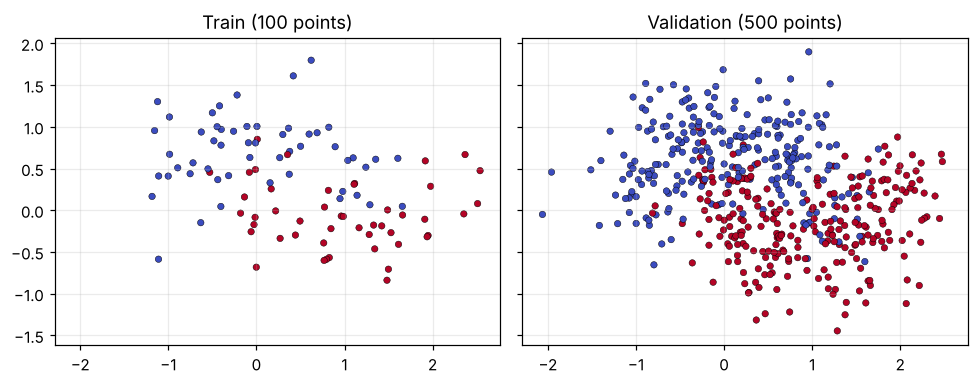

In [2]:
N_TRAIN = 100

X, y = make_moons(n_samples=3000, noise=0.35, random_state=SEED)

# 2000 samples go into a "pool" we can draw training sets from; 1000 are held out.
X_pool, X_hold, y_pool, y_hold = train_test_split(
    X, y, test_size=1000, stratify=y, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_hold, y_hold, test_size=0.5, stratify=y_hold, random_state=SEED
)

X_train, y_train = X_pool[:N_TRAIN], y_pool[:N_TRAIN]
print(f"train={len(X_train)}  val={len(X_val)}  test={len(X_test)}  (pool={len(X_pool)})")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharex=True, sharey=True)
for ax, (Xs, ys, name) in zip(axes, [(X_train, y_train, "Train (100 points)"),
                                     (X_val, y_val, "Validation (500 points)")]):
    ax.scatter(Xs[:, 0], Xs[:, 1], c=ys, cmap="coolwarm", s=18, edgecolor="k", linewidth=0.3)
    ax.set_title(name)
plt.tight_layout()
plt.show()

The two classes overlap heavily: no smooth boundary can classify everything correctly. Any model that gets *every* training point right must be bending its boundary around individual noisy points. That is overfitting.

## 2. Model and training loop

A configurable MLP (so we can vary width, depth and dropout later), plus the usual PyTorch loop split into `train_one_epoch`, `evaluate`, and `fit`.

Two details matter for diagnosing overfitting:

- `evaluate` calls `model.eval()` and uses `torch.no_grad()`, so dropout is off and no gradients are tracked.
- In `fit`, the *training* metrics logged per epoch are also computed with `evaluate`, so the train and validation curves are measured the same way and are directly comparable.

In [3]:
class MLP(nn.Module):
    def __init__(self, hidden=(16,), dropout=0.0, in_dim=2, out_dim=2):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = h
        layers.append(nn.Linear(d, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def make_loader(X, y, batch_size=16, shuffle=False):
    ds = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


loss_fn = nn.CrossEntropyLoss()
val_loader = make_loader(X_val, y_val, batch_size=512)
test_loader = make_loader(X_test, y_test, batch_size=512)

In [4]:
def train_one_epoch(model, loader, optimizer):
    model.train()
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        total_loss += loss_fn(logits, yb).item() * len(xb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(xb)
    return total_loss / n, correct / n


def fit(model, X_tr, y_tr, epochs=300, lr=1e-3, weight_decay=0.0, batch_size=16,
        patience=None, val=None):
    """Train `model` and return a history dict.

    patience=None  -> train for all epochs, keep the final weights.
    patience=k     -> early stopping: stop after k epochs without a new best
                      validation loss, then restore the best weights.
    val            -> optional (X, y) to validate on instead of the global val set
                      (used by the random-label experiment).
    """
    model.to(device)
    train_loader = make_loader(X_tr, y_tr, batch_size=batch_size, shuffle=True)
    train_eval_loader = make_loader(X_tr, y_tr, batch_size=1024)
    v_loader = val_loader if val is None else make_loader(*val, batch_size=512)
    # Adam's weight_decay adds an L2 penalty on the weights
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val, best_state, best_epoch, bad = float("inf"), None, 0, 0

    for epoch in range(1, epochs + 1):
        train_one_epoch(model, train_loader, optimizer)
        tl, ta = evaluate(model, train_eval_loader)
        vl, va = evaluate(model, v_loader)
        for k, v in zip(h, (tl, vl, ta, va)):
            h[k].append(v)

        if vl < best_val:
            best_val, best_epoch, bad = vl, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if patience is not None and bad >= patience:
                break

    h["best_epoch"] = best_epoch      # epoch with the lowest validation loss
    h["stopped_epoch"] = epoch        # epoch where training ended
    if patience is not None:
        model.load_state_dict(best_state)   # restore the best weights
    return h


def new_model(hidden, dropout=0.0, seed=SEED):
    set_seed(seed)                    # same seed -> reproducible init and batch order
    return MLP(hidden=hidden, dropout=dropout)

In [5]:
# Plotting helpers used throughout
def plot_history(h, title="", ax_pair=None):
    if ax_pair is None:
        _, ax_pair = plt.subplots(1, 2, figsize=(10, 3.6))
    ax_loss, ax_acc = ax_pair
    ep = np.arange(1, len(h["train_loss"]) + 1)
    ax_loss.plot(ep, h["train_loss"], label="train")
    ax_loss.plot(ep, h["val_loss"], label="validation")
    ax_loss.axvline(h["best_epoch"], color="gray", ls="--", lw=1, label=f"best val loss (epoch {h['best_epoch']})")
    ax_loss.set_xlabel("epoch"); ax_loss.set_ylabel("cross-entropy loss"); ax_loss.set_title(f"{title} loss")
    ax_loss.legend()
    ax_acc.plot(ep, h["train_acc"], label="train")
    ax_acc.plot(ep, h["val_acc"], label="validation")
    ax_acc.axvline(h["best_epoch"], color="gray", ls="--", lw=1)
    ax_acc.set_xlabel("epoch"); ax_acc.set_ylabel("accuracy"); ax_acc.set_title(f"{title} accuracy")
    ax_acc.legend()


@torch.no_grad()
def plot_boundary(ax, model, Xs, ys, title):
    model.eval()
    pad = 0.6
    xx, yy = np.meshgrid(
        np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300),
        np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300),
    )
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32, device=device)
    pred = model(grid).argmax(1).cpu().numpy().reshape(xx.shape)
    ax.contourf(xx, yy, pred, alpha=0.25, cmap="coolwarm", levels=[-0.5, 0.5, 1.5])
    ax.scatter(Xs[:, 0], Xs[:, 1], c=ys, cmap="coolwarm", s=16, edgecolor="k", linewidth=0.3)
    ax.set_title(title)
    ax.grid(False)

## 3. Experiment 1: a small model vs a big model

Same data, same optimizer, same number of epochs. Only the model capacity differs:

- **small**: one hidden layer of 8 units
- **big**: two hidden layers of 128 units, which has far more parameters than we have training points

We train both for 300 epochs with **no regularization and no early stopping**.

In [6]:
SMALL, BIG = (8,), (128, 128)

small = new_model(SMALL)
big = new_model(BIG)
print(f"small: {n_params(small):>6,} parameters")
print(f"big:   {n_params(big):>6,} parameters   (training points: {len(X_train)})")

h_small = fit(small, X_train, y_train, epochs=300)
h_big = fit(big, X_train, y_train, epochs=300)

for name, h in [("small", h_small), ("big", h_big)]:
    gap = h["train_acc"][-1] - h["val_acc"][-1]
    print(f"{name:>5}: final train acc {h['train_acc'][-1]:.3f} | final val acc {h['val_acc'][-1]:.3f} "
          f"| gap {gap:+.3f} | best val-loss epoch {h['best_epoch']} | final val loss {h['val_loss'][-1]:.3f}")

small:     42 parameters
big:   17,154 parameters   (training points: 100)


small: final train acc 0.860 | final val acc 0.842 | gap +0.018 | best val-loss epoch 294 | final val loss 0.372
  big: final train acc 0.970 | final val acc 0.842 | gap +0.128 | best val-loss epoch 27 | final val loss 1.088


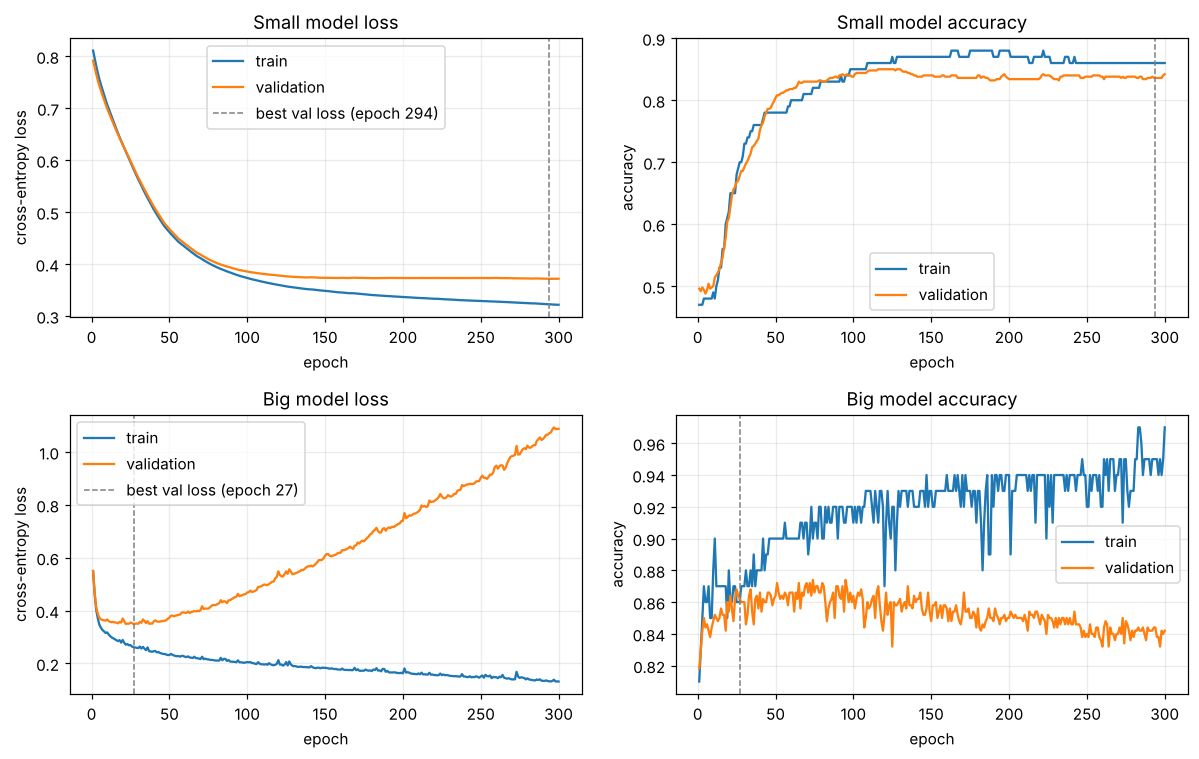

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
plot_history(h_small, "Small model", axes[0])
plot_history(h_big, "Big model", axes[1])
plt.tight_layout()
plt.show()

### How to read these curves

- **Training loss** keeps falling for both models: the optimizer is doing its job.
- For the **big** model, **validation loss reaches a minimum and then climbs back up** while training loss keeps dropping. The dashed line marks that minimum. After it, every extra epoch makes the model *better at the training set and worse on new data*. This divergence is the classic signature of overfitting.
- The gap between the training curve and the validation curve is the **generalization gap**. A wide, growing gap is the symptom.

Note that validation *accuracy* can look deceptively flat while validation *loss* is already getting worse: the model becomes overconfident on the points it gets wrong, which cross-entropy punishes heavily. Watch the loss, not just the accuracy.

### What the model actually learned

Below, the shaded regions are each model's predictions. Top row: the boundary drawn over the **training** points. Bottom row: the *same* boundary drawn over **validation** points the model never saw.

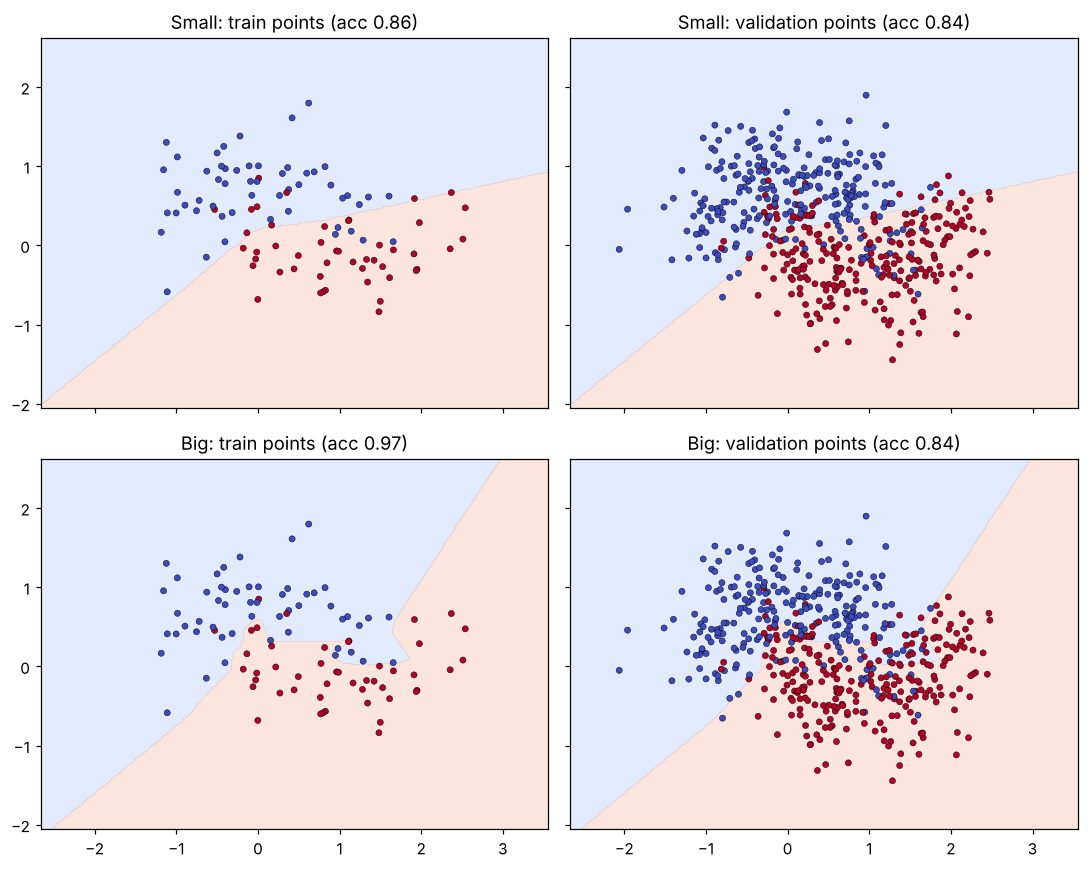

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
for row, (name, m, h) in enumerate([("Small", small, h_small), ("Big", big, h_big)]):
    plot_boundary(axes[row, 0], m, X_train, y_train, f"{name}: train points (acc {h['train_acc'][-1]:.2f})")
    plot_boundary(axes[row, 1], m, X_val, y_val, f"{name}: validation points (acc {h['val_acc'][-1]:.2f})")
plt.tight_layout()
plt.show()

The small model draws a simple, almost straight boundary through the overlap region and accepts that some training points are simply noise (train accuracy about 0.86, and validation is almost the same). The big model bends its boundary and carves out pockets to get individual noisy training points "right", reaching a much higher training accuracy. Those pockets are fitted to noise, not to the true class structure, so validation accuracy does not improve (it is no better than the small model's, and it falls with further training).

## 4. Experiment 2: how model capacity drives overfitting

We sweep the hidden width of a 2-hidden-layer MLP and train each for a fixed 200 epochs (no early stopping), averaging over 3 random seeds.

In [9]:
widths = [1, 2, 4, 8, 16, 32, 64, 128, 256]
seeds = [0, 1, 2]
rows = []
for w in widths:
    r = {"w": w, "params": None, "tl": [], "vl": [], "ta": [], "va": []}
    for s in seeds:
        m = new_model((w, w), seed=s)
        r["params"] = n_params(m)
        h = fit(m, X_train, y_train, epochs=200)
        r["tl"].append(h["train_loss"][-1]); r["vl"].append(h["val_loss"][-1])
        r["ta"].append(h["train_acc"][-1]);  r["va"].append(h["val_acc"][-1])
    rows.append(r)

print(f"{'width':>5} {'params':>8} {'train acc':>10} {'val acc':>8} {'train loss':>11} {'val loss':>9}")
for r in rows:
    print(f"{r['w']:>5} {r['params']:>8,} {np.mean(r['ta']):>10.3f} {np.mean(r['va']):>8.3f} "
          f"{np.mean(r['tl']):>11.3f} {np.mean(r['vl']):>9.3f}")

width   params  train acc  val acc  train loss  val loss
    1        9      0.637    0.615       0.609     0.612
    2       18      0.753    0.726       0.488     0.499
    4       42      0.880    0.843       0.382     0.411
    8      114      0.863    0.840       0.328     0.380
   16      354      0.880    0.862       0.268     0.355
   32    1,218      0.903    0.869       0.222     0.392
   64    4,482      0.920    0.859       0.198     0.493
  128   17,154      0.937    0.851       0.162     0.661
  256   67,074      0.933    0.845       0.141     0.847


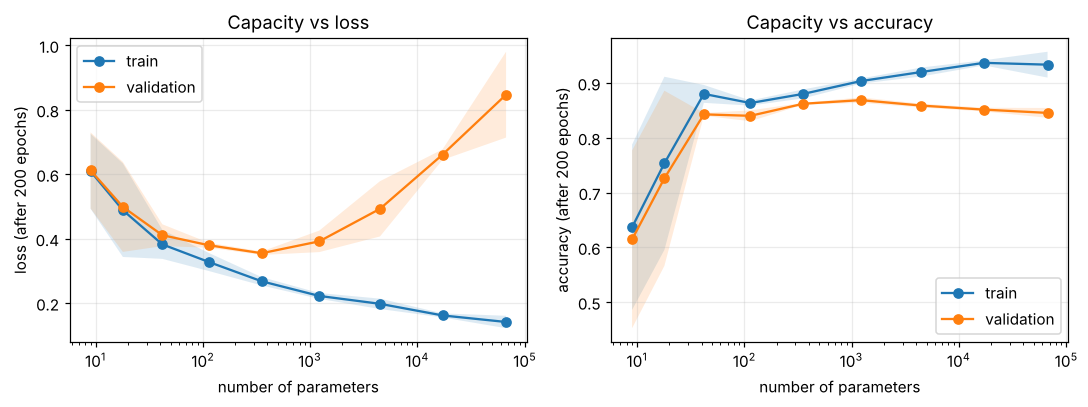

In [10]:
P = [r["params"] for r in rows]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, (a, b, yl) in zip(axes, [("tl", "vl", "loss (after 200 epochs)"), ("ta", "va", "accuracy (after 200 epochs)")]):
    for key, lab in [(a, "train"), (b, "validation")]:
        mean = np.array([np.mean(r[key]) for r in rows]); std = np.array([np.std(r[key]) for r in rows])
        ax.plot(P, mean, marker="o", label=lab)
        ax.fill_between(P, mean - std, mean + std, alpha=0.15)
    ax.set_xscale("log"); ax.set_xlabel("number of parameters"); ax.set_ylabel(yl); ax.legend()
axes[0].set_title("Capacity vs loss"); axes[1].set_title("Capacity vs accuracy")
plt.tight_layout(); plt.show()

Read this as three regimes from left to right:

- **Underfitting** (tiny models): training *and* validation error are both high. The model is too simple to capture the pattern.
- **Good fit** (middle): validation performance is at or near its best.
- **Overfitting** (large models): training keeps improving while validation stops improving or degrades, so the gap opens. Validation *loss* degrades much more visibly than validation *accuracy*.

Notice that "more capacity" does not make things catastrophically worse on accuracy here, but it never helps either, and it costs compute and makes the model overconfident. With data this small and noisy, the extra capacity has nothing real left to learn.

## 5. Experiment 3: more data shrinks the gap

Fix the big architecture and vary only the number of training points, drawn from the pool. This is a *learning curve*.

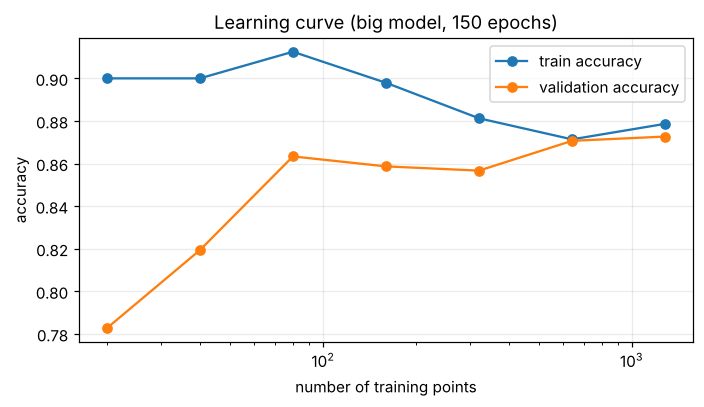

n=   20: train 0.900 | val 0.783 | gap +0.117
n=   40: train 0.900 | val 0.819 | gap +0.081
n=   80: train 0.912 | val 0.863 | gap +0.049
n=  160: train 0.898 | val 0.859 | gap +0.039
n=  320: train 0.881 | val 0.857 | gap +0.025
n=  640: train 0.871 | val 0.871 | gap +0.001
n= 1280: train 0.879 | val 0.873 | gap +0.006


In [11]:
sizes = [20, 40, 80, 160, 320, 640, 1280]
lc = {"ta": [], "va": [], "vl": []}
for n in sizes:
    ta, va, vl = [], [], []
    for s in seeds:
        m = new_model(BIG, seed=s)
        # keep ~7 optimizer steps per epoch so every dataset size gets a comparable training budget
        h = fit(m, X_pool[:n], y_pool[:n], epochs=150, batch_size=max(16, n // 7))
        ta.append(h["train_acc"][-1]); va.append(h["val_acc"][-1]); vl.append(h["val_loss"][-1])
    lc["ta"].append(np.mean(ta)); lc["va"].append(np.mean(va)); lc["vl"].append(np.mean(vl))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(sizes, lc["ta"], marker="o", label="train accuracy")
ax.plot(sizes, lc["va"], marker="o", label="validation accuracy")
ax.set_xscale("log"); ax.set_xlabel("number of training points"); ax.set_ylabel("accuracy")
ax.set_title("Learning curve (big model, 150 epochs)"); ax.legend()
plt.tight_layout(); plt.show()

for n, ta, va in zip(sizes, lc["ta"], lc["va"]):
    print(f"n={n:>5}: train {ta:.3f} | val {va:.3f} | gap {ta - va:+.3f}")

With few points the network fits them well (training accuracy stays high) but validation accuracy lags well behind. As the dataset grows, the gap between the two shrinks steadily, because there are fewer accidental patterns to latch onto and the real structure dominates. Individual points on the curve are noisy (we average only 3 seeds), but the trend is clear. **More (real) data is the most reliable cure for overfitting**, when you can get it.

## 6. Experiment 4: a network can memorize pure noise

Here is the sharpest demonstration that training accuracy proves nothing by itself. We **randomly shuffle the training labels**, so they have no relationship to the inputs at all, and train the big model. Validation uses the *true* labels.

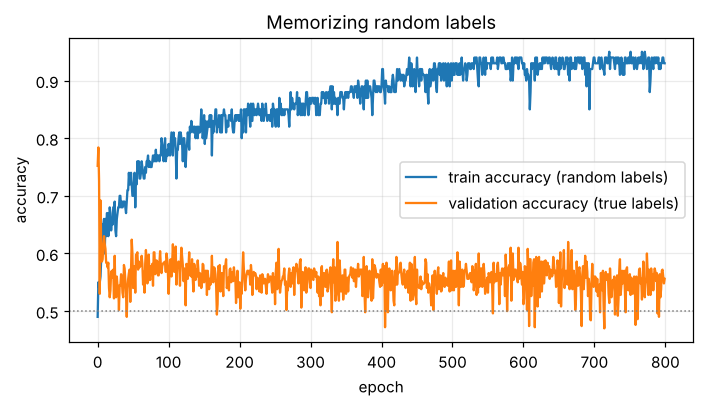

final train acc 0.930 on labels with NO signal | final val acc 0.556


In [12]:
rng = np.random.RandomState(0)
y_train_random = rng.permutation(y_train)      # same class balance, zero signal

m_rand = new_model(BIG)
h_rand = fit(m_rand, X_train, y_train_random, epochs=800, lr=3e-3)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(h_rand["train_acc"], label="train accuracy (random labels)")
ax.plot(h_rand["val_acc"], label="validation accuracy (true labels)")
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.set_title("Memorizing random labels"); ax.legend()
plt.tight_layout(); plt.show()

print(f"final train acc {h_rand['train_acc'][-1]:.3f} on labels with NO signal | final val acc {h_rand['val_acc'][-1]:.3f}")

Training accuracy climbs far above the 50% chance level on labels that carry no information at all, while validation accuracy stays near chance. There was nothing to learn here, so everything the network "learned" is memorization. A network with enough capacity *can* memorize its training set whether or not there is any pattern in it. The training curve alone cannot tell you whether the model has learned a pattern or built a lookup table; **only held-out data can**.

## 7. Remedies

We keep the big model (so it has plenty of capacity to overfit) and compare standard fixes. Each variant changes one thing relative to the baseline.

| Remedy | Idea |
|---|---|
| **Early stopping** | stop at the epoch where validation loss is lowest and restore those weights |
| **Weight decay (L2)** | penalize large weights, which favors smoother functions |
| **Dropout** | randomly zero activations during training so units cannot co-adapt and memorize |
| **Smaller model** | reduce capacity directly |
| **More data** | 10x the training points (here 1000 instead of 100) |

For a fair comparison every variant gets about the same number of optimizer steps per epoch (the 10x-data run uses a proportionally larger batch).

In [13]:
EPOCHS = 300
configs = {
    "baseline (big, no fix)":     dict(hidden=BIG,   dropout=0.0, wd=0.0,  patience=None, n=100),
    "early stopping":             dict(hidden=BIG,   dropout=0.0, wd=0.0,  patience=20,   n=100),
    "weight decay (L2=1e-2)":     dict(hidden=BIG,   dropout=0.0, wd=1e-2, patience=None, n=100),
    "dropout (p=0.3)":            dict(hidden=BIG,   dropout=0.3, wd=0.0,  patience=None, n=100),
    "smaller model":              dict(hidden=SMALL, dropout=0.0, wd=0.0,  patience=None, n=100),
    "more data (10x)":            dict(hidden=BIG,   dropout=0.0, wd=0.0,  patience=None, n=1000),
}

results = {}
for name, c in configs.items():
    per_seed, hist0 = [], None
    for s in seeds:
        m = new_model(c["hidden"], dropout=c["dropout"], seed=s)
        h = fit(m, X_pool[:c["n"]], y_pool[:c["n"]], epochs=EPOCHS, weight_decay=c["wd"],
                patience=c["patience"], batch_size=max(16, c["n"] // 7))
        vl, va = evaluate(m, val_loader)
        tl, ta = evaluate(m, make_loader(X_pool[:c["n"]], y_pool[:c["n"]], batch_size=1024))
        te_l, te_a = evaluate(m, test_loader)
        per_seed.append((ta, va, te_a, vl))
        if s == seeds[0]:
            hist0 = h
    results[name] = {"hist": hist0, "metrics": np.array(per_seed)}

print(f"{'variant':<26} {'train acc':>10} {'val acc':>10} {'test acc':>10} {'val loss':>9} {'gap':>7}")
for name, r in results.items():
    ta, va, tea, vl = r["metrics"].mean(0)
    print(f"{name:<26} {ta:>10.3f} {va:>10.3f} {tea:>10.3f} {vl:>9.3f} {ta - tea:>+7.3f}")
print("\n(mean over", len(seeds), "seeds; 'gap' = train acc - test acc; weights restored to best epoch for early stopping)")

variant                     train acc    val acc   test acc  val loss     gap
baseline (big, no fix)          0.943      0.839      0.868     1.037  +0.075
early stopping                  0.860      0.859      0.877     0.340  -0.017
weight decay (L2=1e-2)          0.877      0.863      0.879     0.331  -0.002
dropout (p=0.3)                 0.927      0.855      0.874     0.669  +0.053
smaller model                   0.863      0.838      0.862     0.377  +0.001
more data (10x)                 0.882      0.866      0.887     0.302  -0.005

(mean over 3 seeds; 'gap' = train acc - test acc; weights restored to best epoch for early stopping)


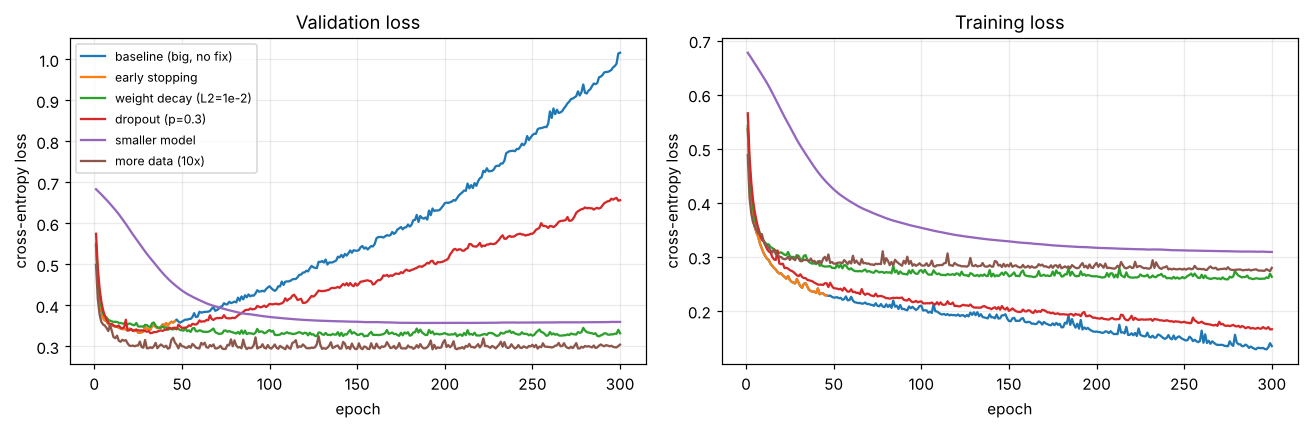

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, r in results.items():
    h = r["hist"]
    ep = np.arange(1, len(h["val_loss"]) + 1)
    axes[0].plot(ep, h["val_loss"], label=name)
    axes[1].plot(ep, np.array(h["train_loss"]) , label=name)
axes[0].set_title("Validation loss"); axes[1].set_title("Training loss")
for ax in axes:
    ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

What to look for:

- The **baseline's validation loss rises** a long way after its minimum, while its training loss keeps falling.
- **Early stopping** ends training near that minimum and restores the best weights, so it avoids the rise.
- **Weight decay** keeps the weights small, so training loss stays higher and validation loss stays flat instead of climbing.
- **Dropout** helps too, but at `p=0.3` and 300 epochs its validation loss still rises noticeably. Regularizers have strengths you must tune, and they combine well with early stopping.
- A **smaller model** has a small gap by construction, but it has a ceiling: too small and it underfits.
- **More data** shrinks the gap without touching the architecture.

Also be honest about the accuracy numbers: with a 500-point test set, accuracy has a standard error of roughly 1.5 percentage points, so the test-accuracy differences between variants are mostly within noise. The clear, consistent signal is in the **validation loss** and the train/validation **gap**. This is one more reason to watch loss curves rather than a single accuracy number.

In practice you combine them: for example, a moderately sized network + dropout + weight decay + early stopping.

> **A methodology note.** Early stopping and hyperparameter choices (the `1e-2`, the `0.3`, `patience=20`) were judged on the **validation** set. That makes validation accuracy slightly optimistic, which is why the table also reports **test** accuracy. Pick your settings on validation, then look at test **once**. If you keep tuning until the test number looks good, you are overfitting to the test set.

### Combining remedies

In [15]:
combo = dict(hidden=BIG, dropout=0.3, wd=1e-3, patience=30)
res = []
for s in seeds:
    m = new_model(combo["hidden"], dropout=combo["dropout"], seed=s)
    h = fit(m, X_train, y_train, epochs=EPOCHS, weight_decay=combo["wd"], patience=combo["patience"])
    _, va = evaluate(m, val_loader)
    _, ta = evaluate(m, make_loader(X_train, y_train, batch_size=1024))
    _, tea = evaluate(m, test_loader)
    res.append((ta, va, tea, h["best_epoch"]))
ta, va, tea, be = np.mean(res, axis=0)
print(f"dropout 0.3 + weight decay 1e-3 + early stopping: train {ta:.3f} | val {va:.3f} | test {tea:.3f} | best epoch ~{be:.0f}")

dropout 0.3 + weight decay 1e-3 + early stopping: train 0.867 | val 0.862 | test 0.885 | best epoch ~49


## 8. Summary: a practical checklist

**Detecting overfitting**
- Always hold out validation data and plot train vs validation *loss* per epoch.
- Validation loss turning upward while training loss falls means you are overfitting.
- A large train/validation gap is the symptom; very high training accuracy on a small dataset is a warning sign, not a success.

**Fixing it, roughly in order of reliability**
1. Get more (or augment) data
2. Use early stopping (almost free)
3. Add weight decay and/or dropout
4. Reduce model capacity
5. Keep the test set untouched until the end

## 9. Exercises

1. **Noise level.** Change `noise=0.35` in `make_moons` to `0.1` and then `0.6`. How do the curves and the gap change? Why does less noise make overfitting less harmful?
2. **Dropout sweep.** Try `p` in `{0.1, 0.3, 0.5, 0.7}`. Plot validation loss against `p`. Is there a "too much" regime (underfitting)?
3. **Weight-decay sweep.** Try `weight_decay` in `{0, 1e-4, 1e-3, 1e-2, 1e-1}`. Choose the best on validation, then report test accuracy once.
4. **Optimizer.** Swap `Adam(weight_decay=...)` for `AdamW`. Adam adds an L2 term to the gradient; AdamW decouples the decay. Does it change the result?
5. **Data augmentation.** Augment the 100 training points by adding small Gaussian jitter (e.g. `std=0.1`) to copies of each point, then retrain the big model. Does the validation loss still rise?
6. **Patience.** Rerun early stopping with `patience` of 3, 20 and 100. What goes wrong at the extremes?
7. **Your own dataset.** Replace `make_moons` with a real tabular dataset, keep the same `fit` loop, and check whether the same curves appear.